# Praktikum 1 : kNN data kafe

Split 70:30, scaling, k=3, evaluasi, dan percobaan k=1 sampai 10 mengikuti contoh.

In [1]:
# Langkah 1 - Load Data
import pandas as pd
data = pd.read_csv('../../dataset_pbl/cafes.csv')
data['source_query'] = data['source_query'].fillna('Tidak tersedia')
data = data[['latitude', 'longitude', 'rating', 'review_count', 'source_query']]
data.head()

,latitude,longitude,rating,review_count,source_query
0,-7.970043,112.631764,4.7,167,Tidak tersedia
1,-7.979534,112.630695,4.5,1575,Tidak tersedia
2,-7.963036,112.625030,4.9,316,Tidak tersedia
3,-7.972555,112.618455,4.6,1772,Tidak tersedia
4,-7.961104,112.651613,4.6,596,Tidak tersedia


In [2]:
# Langkah 2 - Eksplorasi Data
# Cek struktur data informasi deskriptif data

data.info()
data.describe()
data['source_query'].value_counts()

<class 'pandas.DataFrame'>
RangeIndex: 302 entries, 0 to 301
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   latitude      302 non-null    float64
 1   longitude     302 non-null    float64
 2   rating        302 non-null    float64
 3   review_count  302 non-null    int64  
 4   source_query  302 non-null    str    
dtypes: float64(3), int64(1), str(1)
memory usage: 17.2 KB


source_query
Tidak tersedia                126
Cafe Soekarno Hatta Malang     30
Cafe Dinoyo Malang             30
Cafe Ijen Malang               30
Cafe Blimbing Malang           29
Cafe Sawojajar Malang          29
Cafe Sigura gura  Malang       28
Name: count, dtype: int64

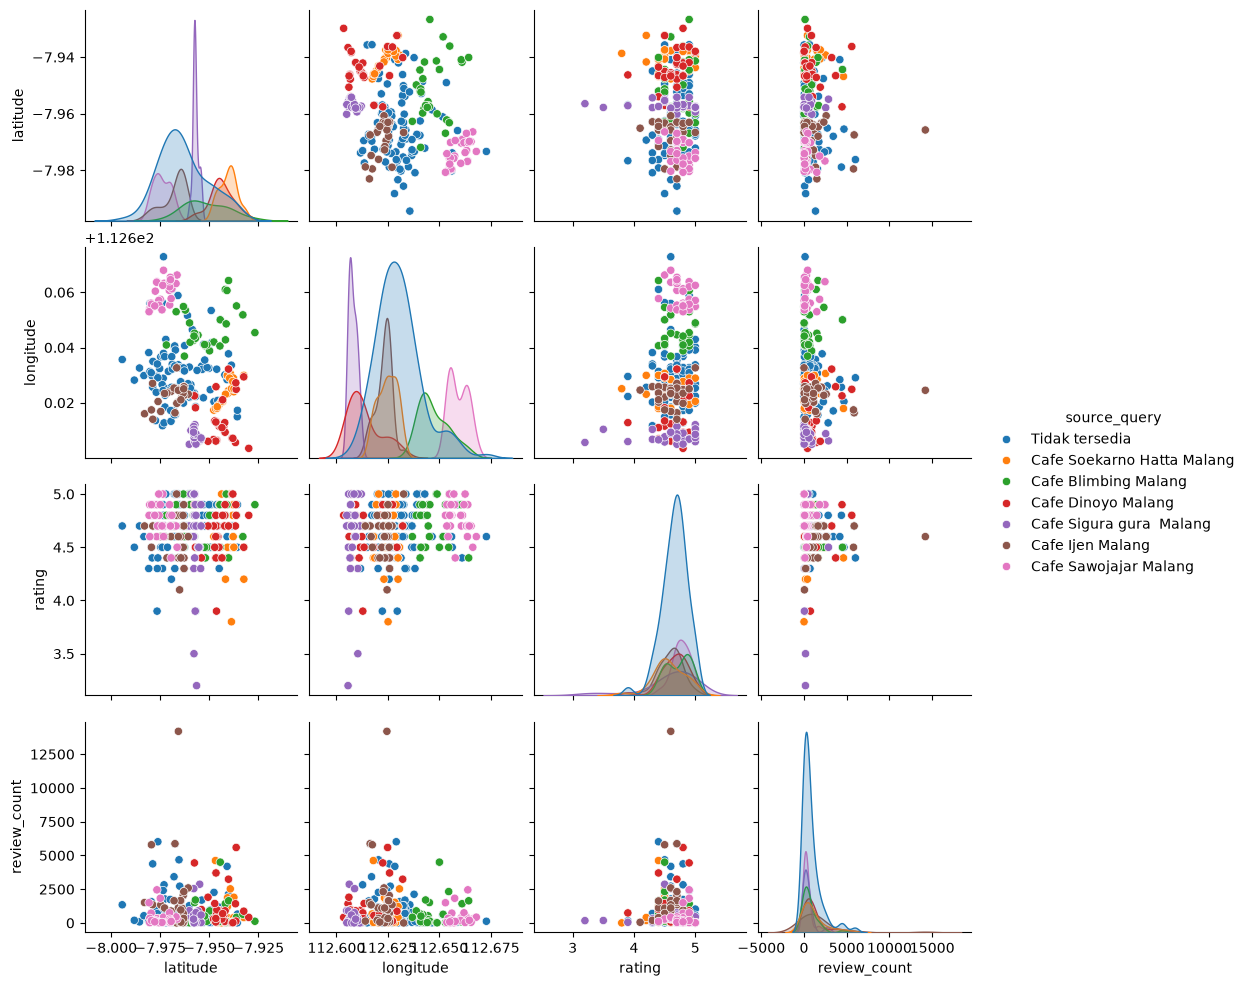

In [3]:
# Langkah 3 - Visualisasi Data
# Lakukan visualisasi data untuk mengetahui distribusi dan korelasi setiap fitur terhadap label.

import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(data, hue='source_query')
plt.show()

In [4]:
# Langkah 4 - Preprocessing
# Pada kasus Iris Dataset, seluruh fitur sudah dalam satuan yang sama yaitu cm.

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = data[['latitude', 'longitude', 'rating', 'review_count']]   # semua kolom kecuali label
y = data['source_query']    # kolom label terakhir

# Split data (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Standardisasi
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [5]:
# Langkah 5 - Buat Model kNN

from sklearn.neighbors import KNeighborsClassifier

# Tentukan nilai K (misalnya 3)
knn = KNeighborsClassifier(n_neighbors=3)

# Latih model
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](7,)","['Cafe Blimbing Malang','Cafe Dinoyo Malang','Cafe Ijen Malang',..., 'Cafe Sigura gura Malang','Cafe Soekarno Hatta Malang','Tidak tersedia']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [6]:
# Langkah 6 - Evaluasi Model kNN

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred = knn.predict(X_test)
print("Akurasi:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Laporan Klasifikasi:\n", classification_report(y_test, y_pred))

Akurasi: 0.6153846153846154
Confusion Matrix:
 [[ 6  0  0  0  0  0  3]
 [ 0  6  0  0  1  0  0]
 [ 0  0  6  0  0  0  5]
 [ 0  0  0  8  0  0  1]
 [ 0  0  0  0  7  0  0]
 [ 0  4  0  0  0  3  0]
 [ 2  4  8  2  1  4 20]]
Laporan Klasifikasi:
                             precision    recall  f1-score   support

      Cafe Blimbing Malang       0.75      0.67      0.71         9
        Cafe Dinoyo Malang       0.43      0.86      0.57         7
          Cafe Ijen Malang       0.43      0.55      0.48        11
     Cafe Sawojajar Malang       0.80      0.89      0.84         9
  Cafe Sigura gura  Malang       0.78      1.00      0.88         7
Cafe Soekarno Hatta Malang       0.43      0.43      0.43         7
            Tidak tersedia       0.69      0.49      0.57        41

                  accuracy                           0.62        91
                 macro avg       0.61      0.70      0.64        91
              weighted avg       0.64      0.62      0.61        91



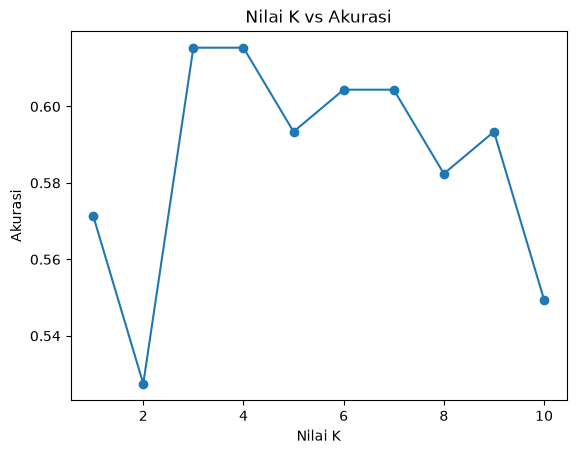

In [7]:
acc = []
for k in range(1, 11):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    acc.append(model.score(X_test, y_test))

plt.plot(range(1, 11), acc, marker='o')
plt.title('Nilai K vs Akurasi')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.show()